# Data Preparation 5: Analysis

### 1. Analyze Lifetime

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [44]:
# use the output of DataPrep 3 
debris_df = pd.read_csv('../Data/Combined.csv')

In [45]:
# check datatypes
print(debris_df.dtypes)

NORAD_CAT_ID            int64
INTLDES                object
SATNAME                object
OBJECT_TYPE            object
COUNTRY                object
SITE                   object
LAUNCH                 object
DECAY                  object
EPOCH                  object
DAYS_SINCE_LAUNCH       int64
REMAINING_LIFETIME      int64
PERIAPSIS             float64
APOAPSIS              float64
ARG_OF_PERICENTER     float64
MEAN_MOTION           float64
ECCENTRICITY          float64
INCLINATION           float64
RA_OF_ASC_NODE        float64
MEAN_ANOMALY          float64
REV_AT_EPOCH          float64
BSTAR                 float64
MEAN_MOTION_DOT       float64
MEAN_MOTION_DDOT      float64
SEMIMAJOR_AXIS        float64
PERIOD                float64
LIFETIME                int64
dtype: object


In [46]:
# summary statistics of lifetime
print(debris_df['LIFETIME'].describe())

count    24438.000000
mean      3585.074965
std       4762.605804
min          0.000000
25%         45.000000
50%       1029.000000
75%       5842.250000
max      23115.000000
Name: LIFETIME, dtype: float64


In [47]:
# summary statistics of lifetime in years
lifetime_years = debris_df['LIFETIME'] / 365.25 # account for leap years
print(lifetime_years.describe())

count    24438.000000
mean         9.815400
std         13.039304
min          0.000000
25%          0.123203
50%          2.817248
75%         15.995209
max         63.285421
Name: LIFETIME, dtype: float64


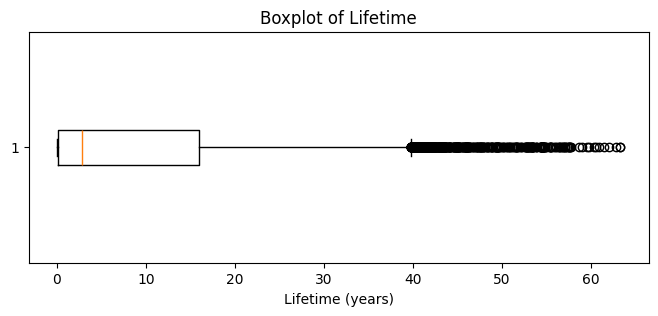

In [48]:
# create a boxplot of the lifetime in years
plt.style.use('default')
plt.figure(figsize=(8, 3))
plt.boxplot(debris_df['LIFETIME']/ 365.25, vert=False)
plt.xlabel('Lifetime (years)')
plt.title('Boxplot of Lifetime')
plt.show()


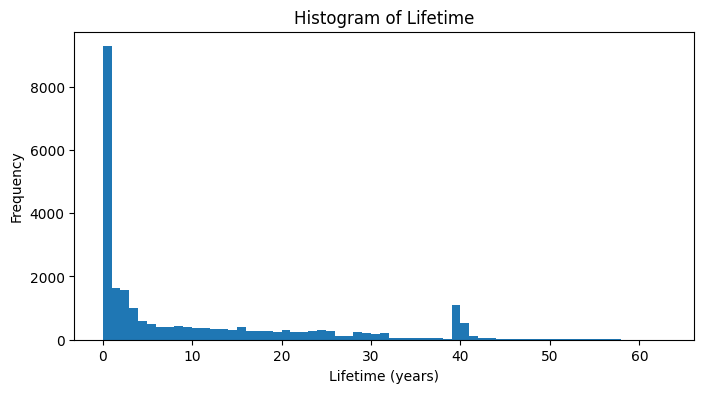

In [49]:
# create histogram of lifetime in years
plt.figure(figsize=(8, 4))
plt.hist(debris_df['LIFETIME']/365, bins=np.arange(0, max(debris_df['LIFETIME']/365), 1))
plt.xlabel('Lifetime (years)')
plt.ylabel('Frequency')
plt.title('Histogram of Lifetime')
plt.show()


In [50]:
# count objects that have lifetime of less than 365 days
print("Objects with lifetime shorter than one year: ", debris_df[debris_df['LIFETIME'] < 365].shape[0])

Objects with lifetime shorter than one year:  9272


#### It could make sense to drop objects with a lifetime of one year or less but since in this all objects shall be considered, they will stay in the dataset.

### 2. Analyze Remaining Lifetime

In [52]:
# describe
debris_df['REMAINING_LIFETIME'].describe()

count    24438.000000
mean       547.980686
std       1224.910504
min          0.000000
25%          6.000000
50%         61.000000
75%        477.000000
max      15767.000000
Name: REMAINING_LIFETIME, dtype: float64

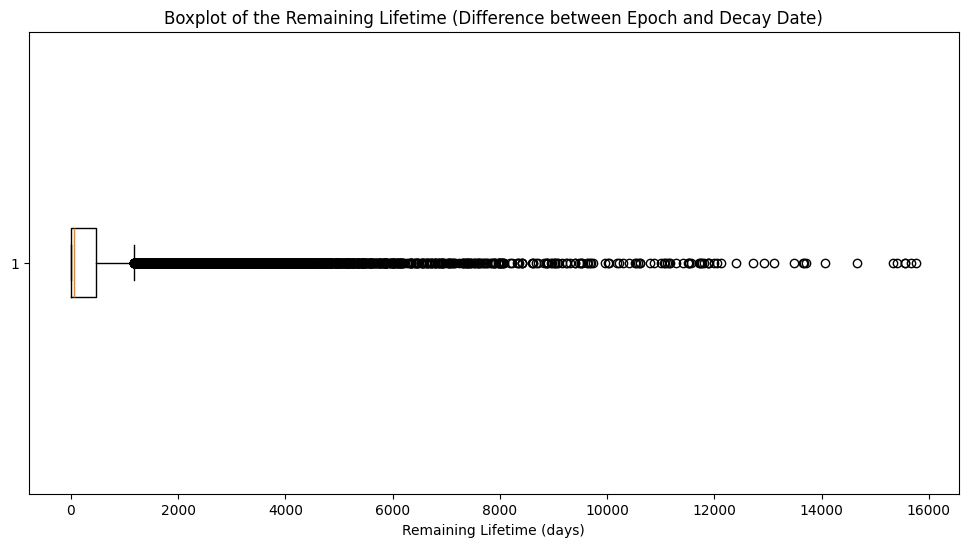

In [53]:
# create a boxplot
plt.figure(figsize=(12, 6))
plt.style.use('default')
plt.boxplot(debris_df['REMAINING_LIFETIME'], vert=False)
plt.xlabel('Remaining Lifetime (days)')
plt.title('Boxplot of the Remaining Lifetime (Difference between Epoch and Decay Date)')
plt.show()

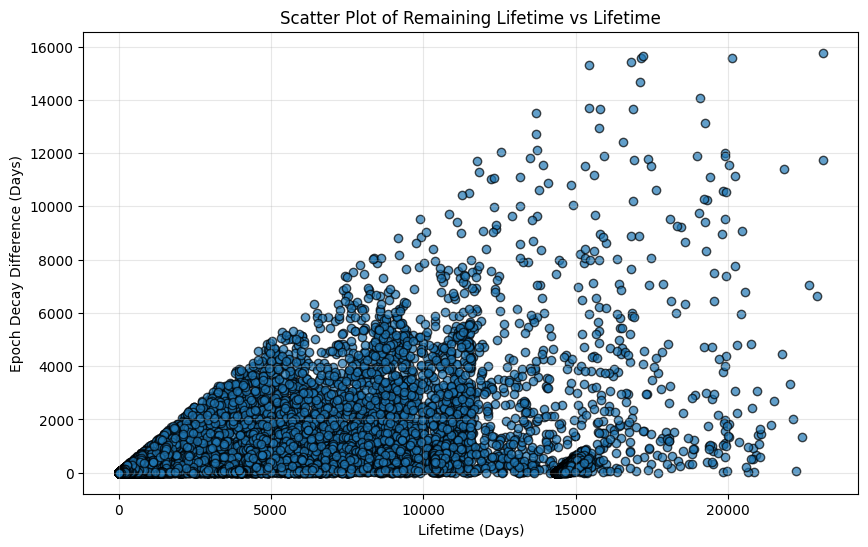

In [54]:
# Create the scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(
    debris_df['LIFETIME'], 
    debris_df['REMAINING_LIFETIME'], 
    alpha=0.7, 
    edgecolors='k'
)

# Add labels and title
plt.title('Scatter Plot of Remaining Lifetime vs Lifetime')
plt.xlabel('Lifetime (Days)')
plt.ylabel('Epoch Decay Difference (Days)')
plt.grid(True, alpha=0.3)
plt.show()

### 3. Feature Correlation

In [58]:
# use the preprocessed data from the MLP since that data is normalized
train_preprocessed_df = pd.read_csv('../Data/TrainPreprocessed.csv')
test_preprocessed_df = pd.read_csv('../Data/TestPreprocessed.csv')
debrisMLP_df = pd.read_csv('../Data/DebrisMLP.csv')

# concat and merge remaining lifetime from debrisMLP_df
debrisCorr_df = pd.concat([train_preprocessed_df, test_preprocessed_df], axis=0)
debrisCorr_df = debrisCorr_df.merge(debrisMLP_df[['NORAD_CAT_ID', 'REMAINING_LIFETIME']], on='NORAD_CAT_ID', how='left')


In [59]:
# drop columnns 
columns_to_drop = [col for col in debrisCorr_df.columns if col.startswith('COUNTRY') or col.startswith('SITE')]
columns_to_drop += ['NORAD_CAT_ID']
debrisCorr_df = debrisCorr_df.drop(columns=columns_to_drop)

In [60]:
# Calculate the correlation matrix
corr_matrix = debrisCorr_df.corr()

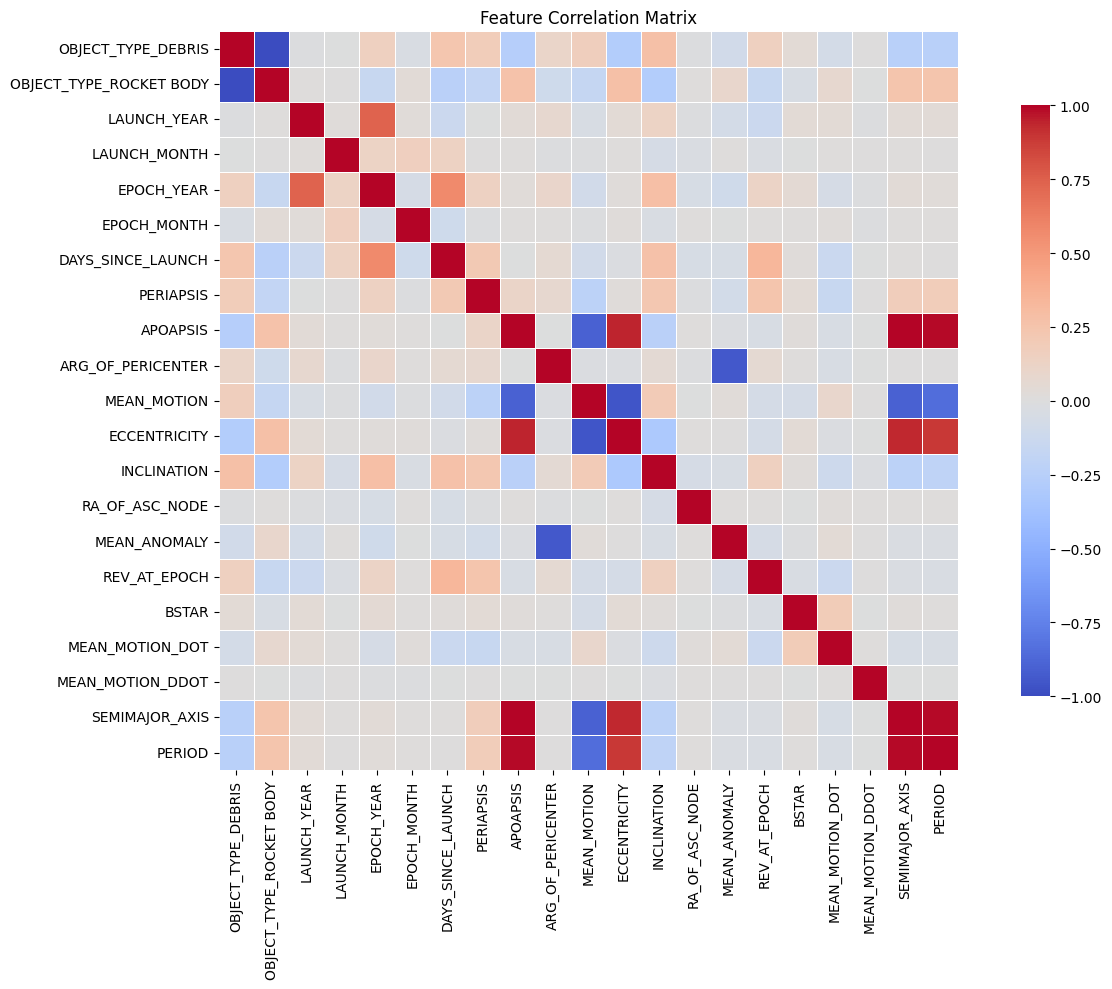

In [61]:
# Heatmap for feature correlation
feature_corr_matrix = corr_matrix.drop(['LIFETIME', 'REMAINING_LIFETIME'], axis=0).drop(['LIFETIME', 'REMAINING_LIFETIME'], axis=1)
plt.style.use('default')
plt.figure(figsize=(14, 10))
sns.heatmap(feature_corr_matrix, annot=False, cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

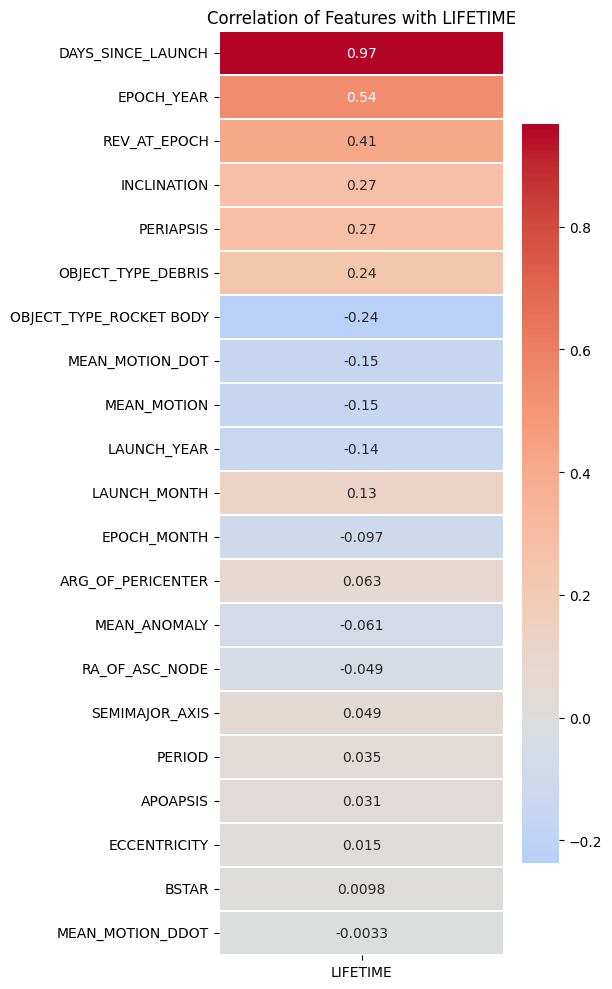

In [64]:
# 2. Heatmap for correlation of all features with the 'LIFETIME' column
lifetime_corr = corr_matrix[['LIFETIME']].drop(['LIFETIME', 'REMAINING_LIFETIME'], axis=0)
lifetime_corr = lifetime_corr.reindex(lifetime_corr['LIFETIME'].abs().sort_values(ascending=False).index)

plt.figure(figsize=(6, 10))
sns.heatmap(lifetime_corr, annot=True, cmap="coolwarm", center=0,
            linewidths=0.2, cbar_kws={"shrink": 0.8})
plt.title("Correlation of Features with LIFETIME")
plt.tight_layout()
plt.show()

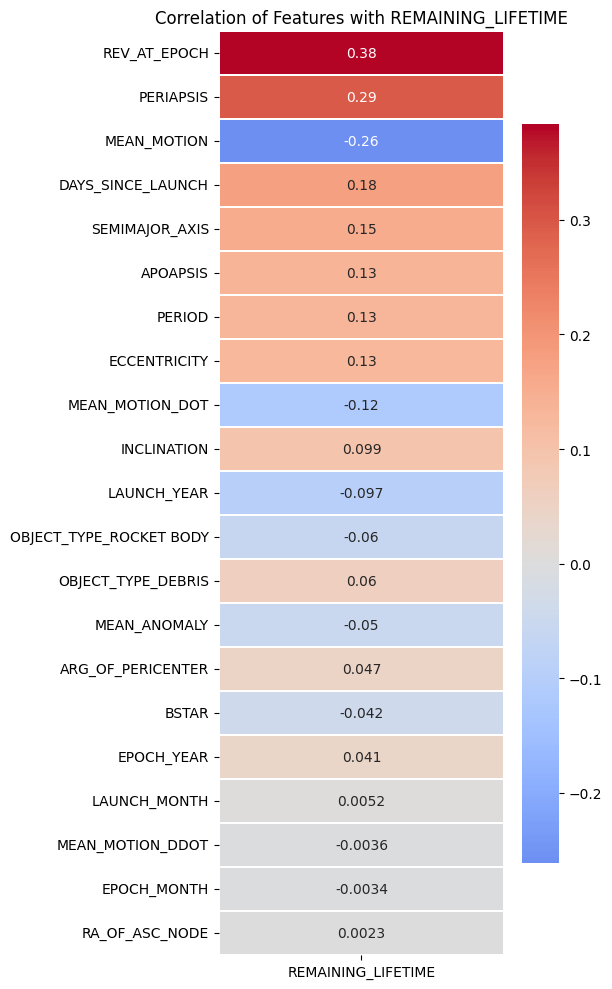

In [65]:
# 3. Heatmap for correlation of all features with the 'REMAINING_LIFETIME' column
remlifetime_corr = corr_matrix[['REMAINING_LIFETIME']].drop(['LIFETIME', 'REMAINING_LIFETIME'], axis=0)
remlifetime_corr = remlifetime_corr.reindex(remlifetime_corr['REMAINING_LIFETIME'].abs().sort_values(ascending=False).index)

plt.figure(figsize=(6, 10))
sns.heatmap(remlifetime_corr, annot=True, cmap="coolwarm", center=0,
            linewidths=0.2, cbar_kws={"shrink": 0.8})
plt.title("Correlation of Features with REMAINING_LIFETIME")
plt.tight_layout()
plt.show()